# Робастные оценки: влияние и устойчивость

Функции влияния, breakdown point и M-оценки при загрязнении и тяжёлых хвостах.


---

## Подготовка среды



In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import optimize, integrate, stats
from scipy.special import roots_legendre
from IPython.display import display

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 115,
    "font.size": 11,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)
print("Среда готова. NumPy:", np.__version__)

Среда готова. NumPy: 2.1.3


---

## Функция влияния и асимптотическая дисперсия

Сравним среднее, медиану и M-оценки Huber и Tukey bisquare в нормальной модели с известным масштабом.


## Модель и сравниваемые оценки

Рассматривается модель сдвига $X_i\sim N(\mu,\sigma^2)$ при $\mu=2$ и $\sigma=1$. Сравниваются среднее, медиана и M-оценки Huber и Tukey bisquare. Для bisquare рассматривается численный корень в окрестности выборочной медианы, поскольку функция оценки немонотонна.


Настроечные параметры для эффективности 95%: Huber c=1.344998; bisquare c=4.685065


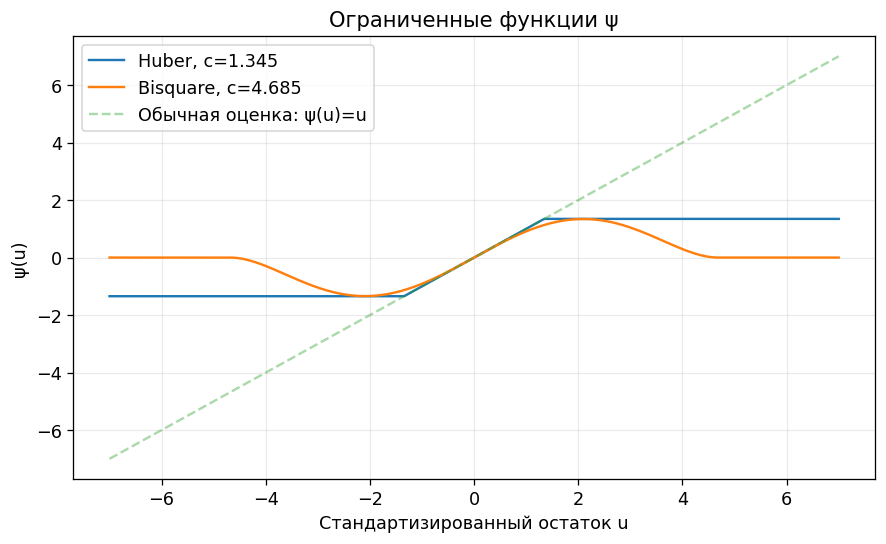

In [14]:
MU, SIGMA = 2.0, 1.0


def psi_huber(u, c):
    u = np.asarray(u, dtype=float)
    return np.clip(u, -c, c)


def dpsi_huber(u, c):
    u = np.asarray(u, dtype=float)
    return (np.abs(u) < c).astype(float)


def psi_bisquare(u, c):
    u = np.asarray(u, dtype=float)
    return np.where(np.abs(u) < c, u * (1 - (u / c)**2)**2, 0.0)


def dpsi_bisquare(u, c):
    u = np.asarray(u, dtype=float)
    return np.where(np.abs(u) < c, (1 - (u / c)**2) * (1 - 5 * (u / c)**2), 0.0)


def centered_root(score, center, scale, c):
    """Найти переход score: плюс -> минус, ближайший к center."""
    scale = max(float(scale), 1e-10)
    # Быстрый путь: рядом с медианой score обычно меняет знак.
    lo0, hi0 = center - 1.5 * scale, center + 1.5 * scale
    if score(lo0) >= 0 >= score(hi0):
        return float(optimize.brentq(score, lo0, hi0, xtol=1e-11))
    for radius in (1.5, 2.5, 4.0, 7.0):
        grid = center + scale * np.linspace(-radius, radius, 71)
        vals = np.array([float(score(t)) for t in grid])
        candidates = [
            (abs((grid[i] + grid[i+1])/2 - center), grid[i], grid[i+1])
            for i in range(len(grid)-1)
            if vals[i] >= 0 >= vals[i+1]
        ]
        if candidates:
            _, lo, hi = min(candidates)
            return float(optimize.brentq(score, lo, hi, xtol=1e-11))
    raise RuntimeError("Не найден локальный M-корень в окрестности медианы")


def m_location(x, kind, c, scale=1.0):
    """M-оценка сдвига, с фиксированным или заранее оценённым scale."""
    x = np.asarray(x, dtype=float)
    center = float(np.median(x))
    psi = psi_huber if kind == "Huber" else psi_bisquare
    return centered_root(
        lambda t: np.mean(psi((x - t) / scale, c)),
        center, scale, c
    )


def normal_psi_moments(kind, c):
    """A=E psi'(Z), B=E psi(Z)^2, Z~N(0,1)."""
    if kind == "Huber":
        A = 2 * stats.norm.cdf(c) - 1
        B = A - 2 * c * stats.norm.pdf(c) + 2 * c**2 * stats.norm.sf(c)
    elif kind == "Bisquare":
        A = integrate.quad(
            lambda z: dpsi_bisquare(z, c) * stats.norm.pdf(z), -c, c,
            epsabs=1e-10
        )[0]
        B = integrate.quad(
            lambda z: psi_bisquare(z, c)**2 * stats.norm.pdf(z), -c, c,
            epsabs=1e-10
        )[0]
    else:
        raise ValueError("Неизвестный метод")
    return A, B


def normal_efficiency(kind, c):
    A, B = normal_psi_moments(kind, c)
    return A**2 / B   # Var(среднего) / Var(M-оценки)

DELTA = 0.95
c_huber = optimize.brentq(lambda c: normal_efficiency("Huber", c) - DELTA, 0.3, 6)
c_bisquare = optimize.brentq(lambda c: normal_efficiency("Bisquare", c) - DELTA, 2, 10)
print(f"Настроечные параметры для эффективности 95%: Huber c={c_huber:.6f}; bisquare c={c_bisquare:.6f}")

u = np.linspace(-7, 7, 700)
plt.figure()
plt.plot(u, psi_huber(u, c_huber), label=f"Huber, c={c_huber:.3f}")
plt.plot(u, psi_bisquare(u, c_bisquare), label=f"Bisquare, c={c_bisquare:.3f}")
plt.plot(u, u, '--', alpha=.4, label="Обычная оценка: ψ(u)=u")
plt.title("Ограниченные функции ψ")
plt.xlabel("Стандартизированный остаток u")
plt.ylabel("ψ(u)")
plt.legend()
plt.show()

На графике представлены функции Губера и bisquare, а также функция обычного среднего.

Функция среднего линейно возрастает, поэтому большие отклонения оказывают всё более сильное влияние на оценку. Функция Губера ограничивает влияние наблюдений при достижении порога (c=1.345). Функция bisquare при больших отклонениях стремится к нулю, фактически исключая влияние сильно удалённых наблюдений.

Таким образом, обе робастные функции ограничивают воздействие выбросов, но делают это по-разному.

## Функции влияния

Функция влияния описывает предельное изменение оценки при добавлении малого загрязнения в точке $z$. Для рассматриваемых оценок она вычисляется по соответствующим формулам ниже.


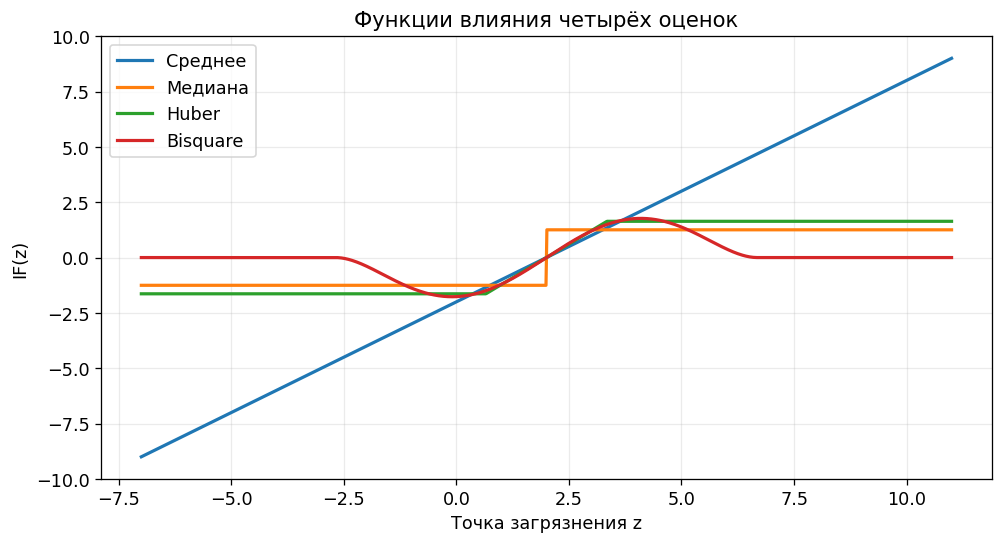

In [15]:
A_h, B_h = normal_psi_moments("Huber", c_huber)
A_b, B_b = normal_psi_moments("Bisquare", c_bisquare)


def if_mean(x):
    return np.asarray(x) - MU


def if_median(x):
    return SIGMA * np.sqrt(np.pi / 2) * np.sign(np.asarray(x) - MU)


def if_huber(x):
    return SIGMA * psi_huber((np.asarray(x) - MU) / SIGMA, c_huber) / A_h


def if_bisquare(x):
    return SIGMA * psi_bisquare((np.asarray(x) - MU) / SIGMA, c_bisquare) / A_b

x_axis = np.linspace(MU - 9, MU + 9, 900)
plt.figure(figsize=(10, 5))
for label, f in [
    ("Среднее", if_mean), ("Медиана", if_median),
    ("Huber", if_huber), ("Bisquare", if_bisquare)
]:
    plt.plot(x_axis, f(x_axis), label=label, linewidth=2)
plt.title("Функции влияния четырёх оценок")
plt.xlabel("Точка загрязнения z")
plt.ylabel("IF(z)")
plt.ylim(-10, 10)
plt.legend()
plt.show()

График функций влияния подтверждает, что выборочное среднее неустойчиво к выбросам, поскольку его функция влияния не ограничена. У медианы, оценки Губера и bisquare функции влияния ограничены.

## Предельная чувствительность к загрязнению

Gross-error sensitivity — максимальный модуль функции влияния. Для среднего она не ограничена; для медианы и рассмотренных M-оценок в выбранной нормальной модели она конечна.


In [16]:
gamma = {
    "Среднее": np.inf,
    "Медиана": SIGMA * np.sqrt(np.pi / 2),
    "Huber": SIGMA * c_huber / A_h,
    "Bisquare": SIGMA * (16 * c_bisquare / (25 * np.sqrt(5))) / A_b,
}

df_gamma = pd.DataFrame({
    "Оценка": list(gamma),
    "Gross-error sensitivity": list(gamma.values()),
})
display(df_gamma.round(5))

,Оценка,Gross-error sensitivity
0,Среднее,inf
1,Медиана,1.25331
2,Huber,1.63750
3,Bisquare,1.76956


Наименьшее значение среди робастных оценок имеет медиана. Следовательно, она обладает наименьшей максимальной локальной чувствительностью к бесконечно малому загрязнению в выбранной модели.

При этом функция влияния bisquare стремится к нулю для достаточно удалённых наблюдений, в отличие от функции Губера, которая выходит на постоянный уровень.

## Проверка асимптотической дисперсии

Для каждой оценки сравниваются теоретическая асимптотическая дисперсия и эмпирическая величина $n\operatorname{Var}(\widehat\mu)$ по независимым симуляциям.


,Оценка,Теоретическое v²,Эффективность к среднему
0,Среднее,1.00000,1.00000
1,Медиана,1.57080,0.63662
2,Huber,1.05263,0.95000
3,Bisquare,1.05263,0.95000


,n,Оценка,Теория v²,Эксперимент n·Var,"Относительная ошибка, %"
0,100,Среднее,1.000,0.915,-8.457
1,100,Медиана,1.571,1.457,-7.229
2,100,Huber,1.053,0.965,-8.352
3,100,Bisquare,1.053,0.969,-7.938
4,400,Среднее,1.000,0.983,-1.736
5,400,Медиана,1.571,1.533,-2.381
6,400,Huber,1.053,1.038,-1.429
7,400,Bisquare,1.053,1.038,-1.394
8,1600,Среднее,1.000,0.991,-0.882
9,1600,Медиана,1.571,1.631,3.824


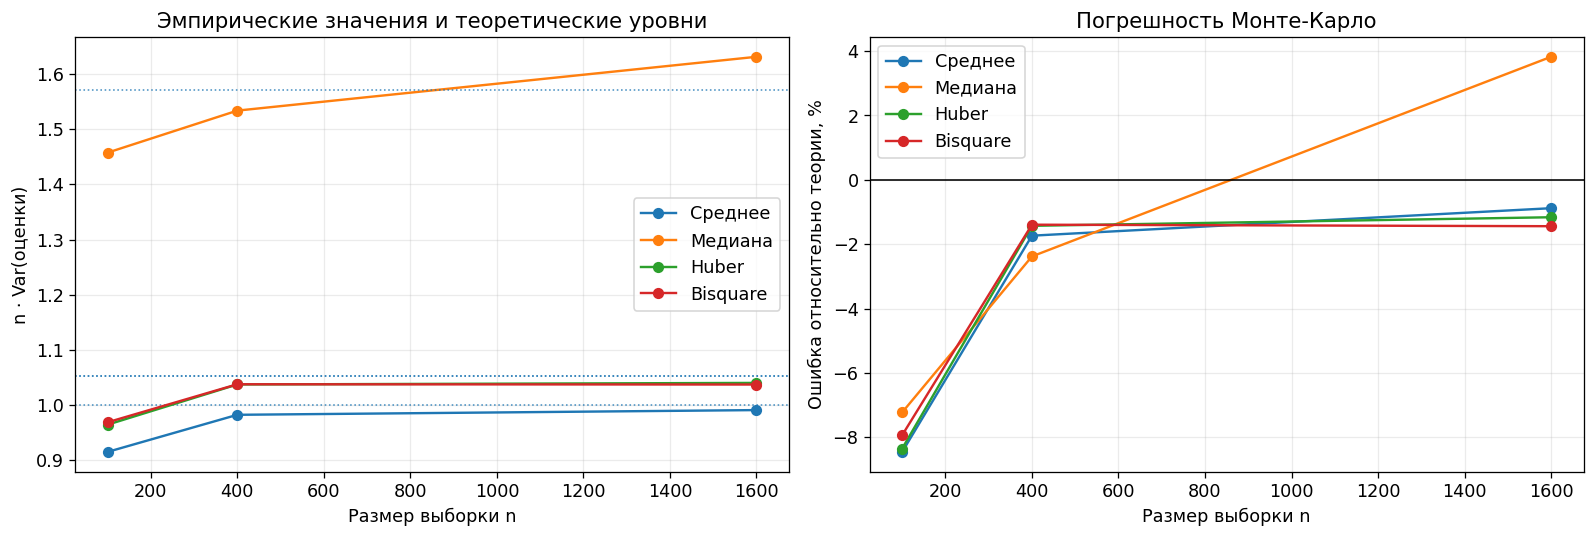

In [17]:
v_theory = {
    "Среднее": SIGMA**2,
    "Медиана": SIGMA**2 * np.pi / 2,
    "Huber": SIGMA**2 * B_h / A_h**2,
    "Bisquare": SIGMA**2 * B_b / A_b**2,
}

display(pd.DataFrame({
    "Оценка": list(v_theory),
    "Теоретическое v²": list(v_theory.values()),
    "Эффективность к среднему": [v_theory["Среднее"] / x for x in v_theory.values()]
}).round(5))

N_SAMPLES = [100, 400, 1600]
REPEATS_1 = 1000
records_1 = []
for n in N_SAMPLES:
    estimates = {k: [] for k in v_theory}
    for _ in range(REPEATS_1):
        x = rng.normal(MU, SIGMA, size=n)
        estimates["Среднее"].append(np.mean(x))
        estimates["Медиана"].append(np.median(x))
        estimates["Huber"].append(m_location(x, "Huber", c_huber, SIGMA))
        estimates["Bisquare"].append(m_location(x, "Bisquare", c_bisquare, SIGMA))
    for method, vals in estimates.items():
        empirical = n * np.var(vals, ddof=1)
        records_1.append({
            "n": n, "Оценка": method,
            "Теория v²": v_theory[method],
            "Эксперимент n·Var": empirical,
            "Относительная ошибка, %": 100 * (empirical / v_theory[method] - 1)
        })

df_variances = pd.DataFrame(records_1)
display(df_variances.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for method in v_theory:
    part = df_variances[df_variances["Оценка"] == method]
    axes[0].plot(part["n"], part["Эксперимент n·Var"], 'o-', label=method)
    axes[0].axhline(v_theory[method], linestyle=':', linewidth=1, alpha=.8)
axes[0].set(xlabel="Размер выборки n", ylabel="n · Var(оценки)", title="Эмпирические значения и теоретические уровни")
axes[0].legend()

for method in v_theory:
    part = df_variances[df_variances["Оценка"] == method]
    axes[1].plot(part["n"], part["Относительная ошибка, %"], 'o-', label=method)
axes[1].axhline(0, color='black', linewidth=1)
axes[1].set(xlabel="Размер выборки n", ylabel="Ошибка относительно теории, %", title="Погрешность Монте-Карло")
axes[1].legend()
plt.tight_layout()
plt.show()

Теоретическая асимптотическая дисперсия среднего составила 1, медианы — 1.5708, оценок Губера и bisquare — 1.05263.

В эксперименте сравнивались теоретические значения $v^2$ и эмпирические значения $$n\cdot\operatorname{Var}(\widehat{\mu})$$ при размерах выборки 100, 400 и 1600.

Полученные результаты в целом согласуются с теорией. Например, при n=1600 эмпирические значения для среднего, Губера и bisquare составили 0.991, 1.040 и 1.037 соответственно, что близко к теоретическим значениям.

Небольшие расхождения обусловлены конечным размером выборок и случайностью эксперимента Монте-Карло. Оценки Губера и bisquare обеспечивают эффективность 95% относительно среднего при нормальном распределении.



### Результат

В нормальной модели среднее имеет наименьшую асимптотическую дисперсию, но его влияние не ограничено. Медиана и M-оценки Huber и bisquare ограничивают влияние отдельных удалённых наблюдений. Эмпирические значения $n\operatorname{Var}(\widehat\mu)$ в целом согласуются с теоретическими расчётами.


---

## Breakdown point медианы

Replacement breakdown point медианы составляет около 50%: меньше этой доли произвольно больших замен недостаточно, чтобы сделать её неограниченной. Для среднего достаточно одной замены. Ниже это свойство проверяется на конечной выборке.


### Эксперимент: рост величины выброса

В выборке из 200 наблюдений доля заменяется одинаковым значением $B$. Для нескольких долей загрязнения увеличивается $B$ и сравниваются среднее и медиана. Для чётного размера выборки при ровно 50% замен медиана усредняет два центральных значения, поэтому также может расти вместе с $B$.


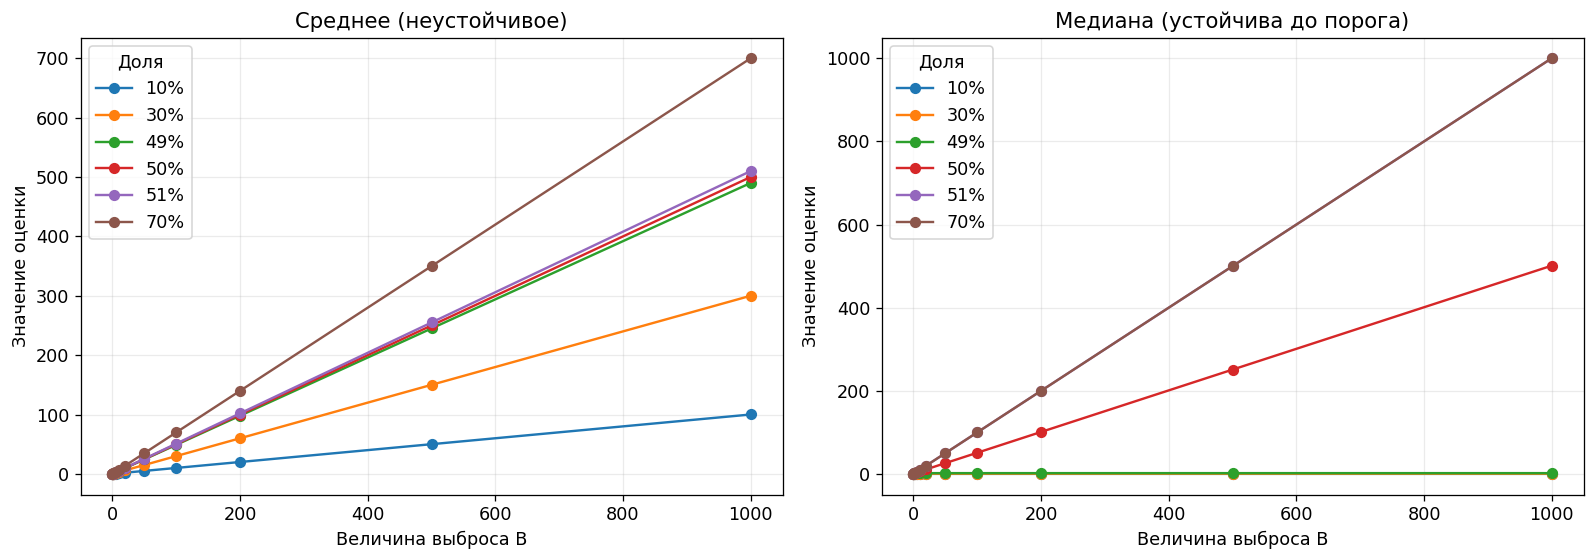

,Доля выбросов,Величина выброса,Среднее,Медиана
10,0.10,1000,100.038,0.111
21,0.30,1000,300.024,0.477
32,0.49,1000,490.007,1.860
43,0.50,1000,500.017,500.966
54,0.51,1000,510.020,1000.000
65,0.70,1000,699.985,1000.000


In [18]:
rng_bp = np.random.default_rng(103)
base = rng_bp.normal(0, 1, 200)
levels = [0.10, 0.30, 0.49, 0.50, 0.51, 0.70]
B_VALUES = np.array([0, 1, 2, 5, 10, 20, 50, 100, 200, 500, 1000])

results_bp = []
for eps in levels:
    m = int(200 * eps)
    for B in B_VALUES:
        changed = base.copy()
        changed[:m] = B
        results_bp.append({
            "Доля выбросов": eps, "Величина выброса": B,
            "Среднее": np.mean(changed), "Медиана": np.median(changed)
        })
df_bp = pd.DataFrame(results_bp)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for eps in levels:
    p = df_bp[df_bp["Доля выбросов"] == eps]
    axes[0].plot(p["Величина выброса"], p["Среднее"], 'o-', label=f"{eps:.0%}")
    axes[1].plot(p["Величина выброса"], p["Медиана"], 'o-', label=f"{eps:.0%}")
for ax, title in zip(axes, ["Среднее (неустойчивое)", "Медиана (устойчива до порога)"]):
    ax.set(xlabel="Величина выброса B", ylabel="Значение оценки", title=title)
    ax.legend(title="Доля")
plt.tight_layout()
plt.show()

display(df_bp[df_bp["Величина выброса"] == 1000].round(3))

На графиках исследовалось изменение среднего и медианы при увеличении величины выбросов для различных долей загрязнения.

Выборочное среднее увеличивается практически линейно с ростом величины выбросов даже при загрязнении 10%.

Медиана сохраняет ограниченность при доле выбросов менее 50%. Например, при 49% загрязнения и величине выброса 1000 значение медианы составило 1.860, тогда как среднее достигло 490.007.

При доле загрязнения 50% медиана резко возрастает, а при 51% совпадает со значением выброса 1000.

Полученные результаты подтверждают, что breakdown point медианы составляет примерно 50%.



### Эксперимент: точность при загрязнении

Для каждой доли загрязнения проводится 250 повторов при $B=20$. Сравниваются смещение, стандартное отклонение, RMSE и доля оценок с абсолютной ошибкой меньше 0.5.


,Доля,Оценка,Смещение,Ст. отклонение,RMSE,P(|ошибка| < 0.5)
0,0.00,Среднее,-0.011,0.069,0.070,1.000
1,0.00,Медиана,-0.009,0.091,0.091,1.000
2,0.10,Среднее,2.000,0.068,2.001,0.000
3,0.10,Медиана,0.128,0.094,0.159,1.000
4,0.20,Среднее,4.002,0.067,4.002,0.000
5,0.20,Медиана,0.326,0.109,0.344,0.924
6,0.30,Среднее,6.005,0.062,6.005,0.000
7,0.30,Медиана,0.561,0.111,0.572,0.300
8,0.40,Среднее,8.000,0.058,8.000,0.000
9,0.40,Медиана,0.961,0.145,0.972,0.000


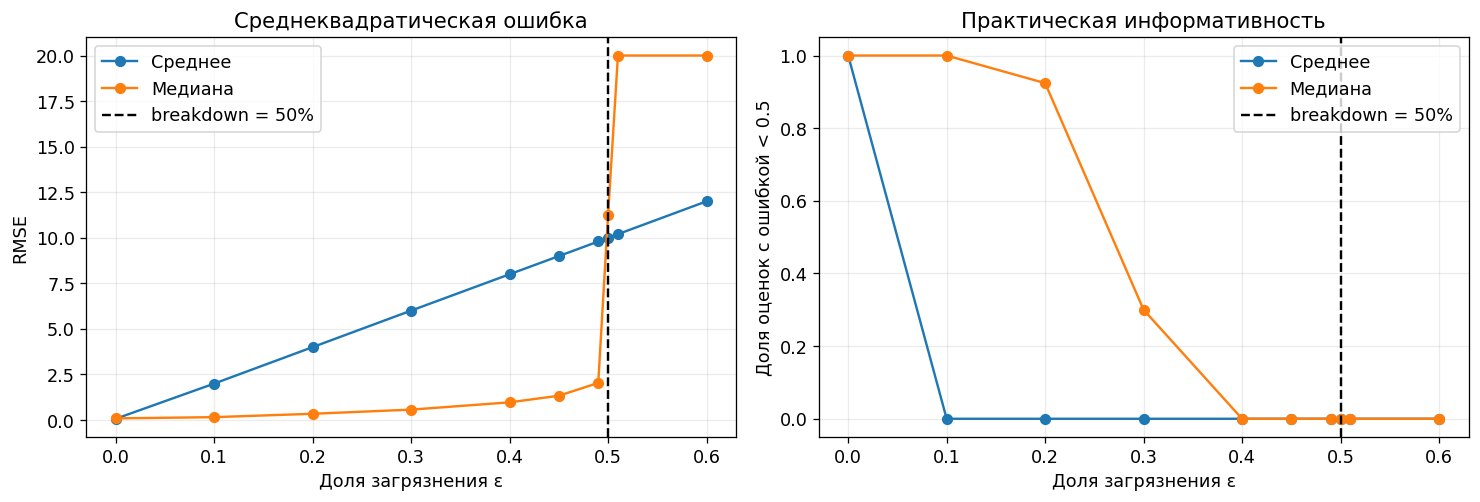

In [19]:
REPEATS_BP = 250
fixed_B = 20.0
records_bp_mc = []
rng_bp_mc = np.random.default_rng(104)
for eps in [0, .1, .2, .3, .4, .45, .49, .50, .51, .6]:
    m = int(round(200 * eps))
    values = {"Среднее": [], "Медиана": []}
    for _ in range(REPEATS_BP):
        x = rng_bp_mc.normal(0, 1, 200)
        x[:m] = fixed_B
        values["Среднее"].append(np.mean(x))
        values["Медиана"].append(np.median(x))
    for method, est in values.items():
        est = np.asarray(est)
        records_bp_mc.append({
            "Доля": eps, "Оценка": method,
            "Смещение": np.mean(est),
            "Ст. отклонение": np.std(est, ddof=1),
            "RMSE": np.sqrt(np.mean(est**2)),
            "P(|ошибка| < 0.5)": np.mean(np.abs(est) < 0.5)
        })
df_bp_mc = pd.DataFrame(records_bp_mc)
display(df_bp_mc.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for method in ["Среднее", "Медиана"]:
    p = df_bp_mc[df_bp_mc["Оценка"] == method]
    axes[0].plot(p["Доля"], p["RMSE"], 'o-', label=method)
    axes[1].plot(p["Доля"], p["P(|ошибка| < 0.5)"], 'o-', label=method)
for ax in axes:
    ax.axvline(.5, linestyle='--', color='black', label="breakdown = 50%")
    ax.set_xlabel("Доля загрязнения ε")
    ax.legend()
axes[0].set(ylabel="RMSE", title="Среднеквадратическая ошибка")
axes[1].set(ylabel="Доля оценок с ошибкой < 0.5", title="Практическая информативность")
plt.tight_layout()
plt.show()

Для дополнительного исследования были вычислены смещение, стандартное отклонение, RMSE и доля оценок с абсолютной ошибкой менее 0.5.

При увеличении доли загрязнения качество обеих оценок ухудшается, однако среднее теряет точность значительно быстрее.

Медиана сохраняет существенно меньшую ошибку при умеренном загрязнении. Например, при 20% выбросов её RMSE составила 0.344, а для среднего — 4.002.

При приближении к 50% загрязнения ошибка медианы также увеличивается, и оценка перестаёт быть достаточно информативной по выбранному критерию ещё до достижения breakdown point.

### Результат

Экспериментально подтверждён breakdown point медианы на уровне 50%. При меньших долях загрязнения медиана остаётся ограниченной даже при произвольно больших выбросах, в то время как среднее не обладает такой устойчивостью.

Однако нахождение ниже breakdown point не гарантирует высокой точности: с увеличением доли выбросов информативность медианы постепенно снижается.

---

## M-оценки при неизвестном масштабе

Далее рассматриваются M-оценки положения, когда масштаб заранее неизвестен и оценивается по MAD.


### Оценка масштаба по MAD

Для нормальной модели MAD нормируется коэффициентом $1/\Phi^{-1}(0.75)\approx1.4826$, что даёт оценку масштаба, сопоставимую со стандартным отклонением. Полученная оценка подставляется в уравнение M-оценки положения.


In [20]:
MAD_NORMAL_FACTOR = 1 / stats.norm.ppf(.75)


def mad_scale(x, model="normal"):
    x = np.asarray(x, dtype=float)
    raw = float(np.median(np.abs(x - np.median(x))))
    # Для стандартного Коши медиана |X| = 1, а для N(0,1) = Φ^{-1}(.75).
    factor = MAD_NORMAL_FACTOR if model == "normal" else 1.0
    return max(factor * raw, 1e-10)

sample = np.random.default_rng(105).normal(2, 1.5, 1000)
s = mad_scale(sample, model="normal")
print(f"Истинное σ=1.5; оценка σ_MAD={s:.4f}")
print(f"Huber location: {m_location(sample, 'Huber', c_huber, s):.4f}")
print(f"Bisquare location: {m_location(sample, 'Bisquare', c_bisquare, s):.4f}")

Истинное σ=1.5; оценка σ_MAD=1.4019
Huber location: 2.0355
Bisquare location: 2.0358


### Настройка эффективности

Параметры Huber и bisquare подбираются так, чтобы асимптотическая эффективность относительно среднего в нормальной модели составляла 95%.


Huber:    c = 1.344998, Δ = 0.950000
Bisquare: c = 4.685065, Δ = 0.950000


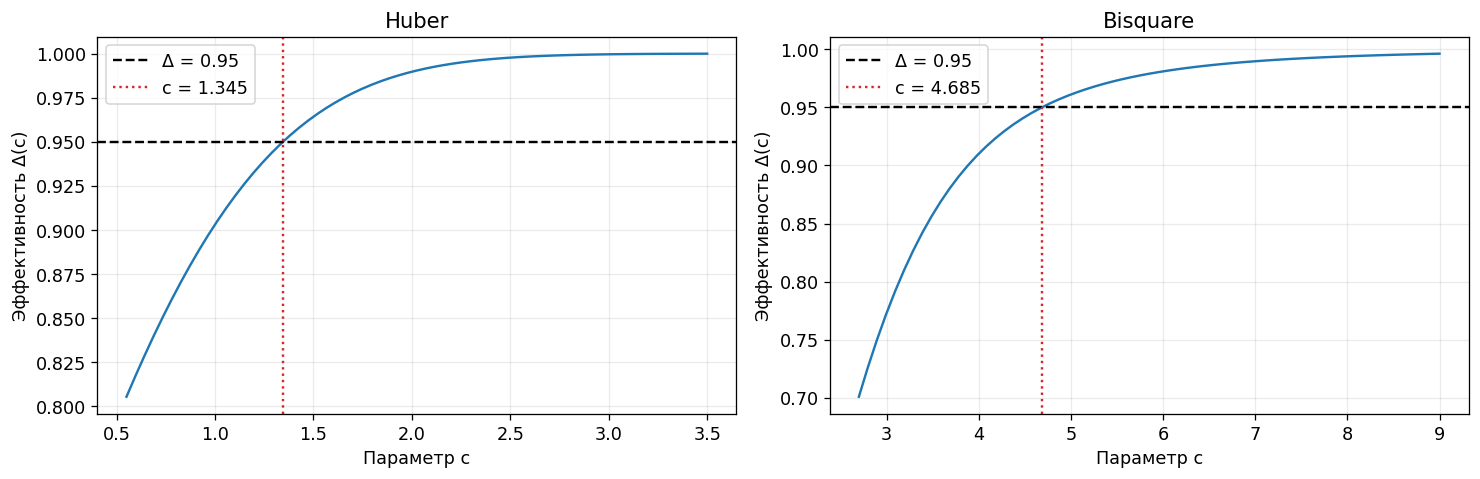

In [21]:
print(f"Huber:    c = {c_huber:.6f}, Δ = {normal_efficiency('Huber', c_huber):.6f}")
print(f"Bisquare: c = {c_bisquare:.6f}, Δ = {normal_efficiency('Bisquare', c_bisquare):.6f}")

c1 = np.linspace(.55, 3.5, 65)
c2 = np.linspace(2.7, 9, 65)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
for ax, kind, grid, cstar in [
    (axes[0], "Huber", c1, c_huber),
    (axes[1], "Bisquare", c2, c_bisquare)
]:
    e = [normal_efficiency(kind, c) for c in grid]
    ax.plot(grid, e)
    ax.axhline(.95, color='black', linestyle='--', label="Δ = 0.95")
    ax.axvline(cstar, color='tab:red', linestyle=':', label=f"c = {cstar:.3f}")
    ax.set(xlabel="Параметр c", ylabel="Эффективность Δ(c)", title=kind)
    ax.legend()
plt.tight_layout()
plt.show()

Параметры функций Губера и bisquare подбирались таким образом, чтобы асимптотическая эффективность относительно среднего в нормальной модели составляла 95%.

Получены следующие значения:

Губер: $c=1.344998$

Bisquare: $c=4.685065$

На графиках видно, что при выбранных параметрах обе кривые достигают уровня эффективности 0.95. Таким образом, найденные значения обеспечивают заданный баланс между эффективностью в нормальной модели и ограничением влияния выбросов.

### Смещение при точечном загрязнении

Рассматривается смесь $F_{\varepsilon,z}=(1-\varepsilon)N(0,1)+\varepsilon\delta_z$. Сначала вычисляется локальное приближение смещения через функцию влияния; затем оно сравнивается с численным расчётом для конечной доли загрязнения.


In [22]:
EPSILON = 0.10  # заданная нами доля загрязнения = 10%
maxbias_small = pd.DataFrame({
    "Оценка": ["Huber", "Bisquare"],
    "γ*": [gamma["Huber"], gamma["Bisquare"]],
    "Доля ε": [EPSILON, EPSILON],
    "Локальная оценка maxbias ≈ ε·γ*": [EPSILON * gamma["Huber"], EPSILON * gamma["Bisquare"]]
})
display(maxbias_small.round(5))

,Оценка,γ*,Доля ε,Локальная оценка maxbias ≈ ε·γ*
0,Huber,1.63750,0.1,0.16375
1,Bisquare,1.76956,0.1,0.17696


Полученные значения являются локальными приближениями максимального смещения при малой доле загрязнения, а не строгими верхними границами.

### Популяционное смещение в зависимости от точки загрязнения

Для каждого $z$ численно находится оценка положения в загрязнённой модели. Масштаб MAD пересчитывается для этой модели, а интеграл по нормальной компоненте вычисляется квадратурой. Это детерминированная популяционная оценка, а не симуляция конечной выборки.


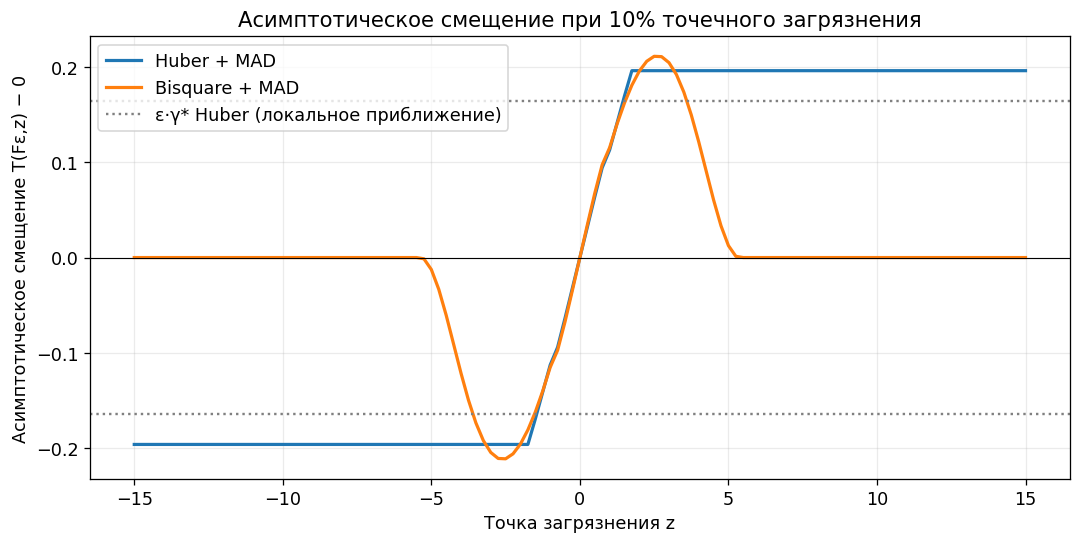

,Оценка,max |bias(z)| на исследованном диапазоне,Локальное приближение ε·γ*,z максимума |bias|
0,Huber,0.1958,0.1637,8.25
1,Bisquare,0.2108,0.1770,2.50


Внимание: максимум по конечной сетке z в [-15,15] — не доказанный глобальный супремум.


In [23]:
# Нормальная составляющая смеси. Квадратура Гаусса–Лежандра на [-9, 9].
quad_nodes_0, quad_weights_0 = roots_legendre(900)
normal_nodes = 9 * quad_nodes_0
normal_weights = 9 * quad_weights_0 * stats.norm.pdf(normal_nodes)


def contaminated_median(eps, z):
    """Точная популяционная медиана (generalized quantile) N(0,1)+atom(z)."""
    if eps == 0:
        return 0.0
    before = (1 - eps) * stats.norm.cdf(z)
    if before >= .5:
        return float(stats.norm.ppf(.5 / (1 - eps)))
    if before + eps >= .5:
        return float(z)
    return float(stats.norm.ppf((.5 - eps) / (1 - eps)))


def contaminated_mad(eps, z, center):
    """Популяционная медиана |X-center| под нормальной+точечной смесью."""
    def cdf_abs(d):
        gauss = (1 - eps) * (
            stats.norm.cdf(center + d) - stats.norm.cdf(center - d)
        )
        atom = eps if abs(z - center) <= d else 0.0
        return gauss + atom
    upper = max(5.0, abs(z - center) + 2)
    # Двоичный поиск работает и когда медиана совпадает со скачком CDF.
    lo = 0.0
    hi = upper
    for _ in range(55):
        mid = .5 * (lo + hi)
        if cdf_abs(mid) >= .5:
            hi = mid
        else:
            lo = mid
    return hi


def contaminated_m_location(eps, z, kind, c):
    center = contaminated_median(eps, z)
    scale = max(MAD_NORMAL_FACTOR * contaminated_mad(eps, z, center), 1e-9)
    psi = psi_huber if kind == "Huber" else psi_bisquare
    def score(t):
        u = (normal_nodes - t) / scale
        normal_part = np.dot(normal_weights, psi(u, c))
        atom_part = float(psi((z - t) / scale, c))
        return (1 - eps) * normal_part + eps * atom_part
    return centered_root(score, center, scale, c)

Z_CONTAM = np.linspace(-15, 15, 121)
bias_h = np.array([contaminated_m_location(EPSILON, z, "Huber", c_huber) for z in Z_CONTAM])
bias_b = np.array([contaminated_m_location(EPSILON, z, "Bisquare", c_bisquare) for z in Z_CONTAM])

plt.figure(figsize=(11, 5))
plt.plot(Z_CONTAM, bias_h, label="Huber + MAD", linewidth=2)
plt.plot(Z_CONTAM, bias_b, label="Bisquare + MAD", linewidth=2)
plt.axhline(EPSILON * gamma["Huber"], color='gray', ls=':', label="ε·γ* Huber (локальное приближение)")
plt.axhline(-EPSILON * gamma["Huber"], color='gray', ls=':')
plt.axhline(0, color='black', lw=0.7)
plt.xlabel("Точка загрязнения z")
plt.ylabel("Асимптотическое смещение T(Fε,z) − 0")
plt.title("Асимптотическое смещение при 10% точечного загрязнения")
plt.legend()
plt.show()

bias_table = pd.DataFrame({
    "Оценка": ["Huber", "Bisquare"],
    "max |bias(z)| на исследованном диапазоне": [np.max(abs(bias_h)), np.max(abs(bias_b))],
    "Локальное приближение ε·γ*": [EPSILON * gamma["Huber"], EPSILON * gamma["Bisquare"]],
    "z максимума |bias|": [Z_CONTAM[np.argmax(abs(bias_h))], Z_CONTAM[np.argmax(abs(bias_b))]],
})
display(bias_table.round(4))
print("Внимание: максимум по конечной сетке z в [-15,15] — не доказанный глобальный супремум.")

Для оценки Губера при удалении точки загрязнения от центра смещение выходит на постоянный уровень. Это объясняется ограничением функции влияния.

Для bisquare смещение сначала возрастает, а затем уменьшается практически до нуля, поскольку сильно удалённые наблюдения получают нулевой вес в функции оценки.

Полученные значения превышают локальные приближения из предыдущего пункта. Это связано с тем, что доля загрязнения 10% уже не является бесконечно малой, а оценка масштаба MAD пересчитывается с учётом загрязнённого распределения.

### Проверка на распределении Коши

Параметры Huber и bisquare, подобранные для нормальной модели, применяются к стандартному распределению Коши без перенастройки. Масштаб оценивается raw MAD, соответствующим калибровке Коши. Сравниваются теоретическая асимптотическая дисперсия робастных оценок и результаты симуляций.


,M-оценка,Параметр c (из нормальной модели),Теоретическое v² для Коши
0,Huber,1.34500,2.84251
1,Bisquare,4.68506,2.35029


,n,Оценка,Теоретическое v²,Эксперимент n·Var,"Относительная ошибка, %"
0,200,Huber,2.8425,2.8936,1.7966
1,200,Bisquare,2.3503,2.4729,5.2154
2,800,Huber,2.8425,2.8258,-0.5893
3,800,Bisquare,2.3503,2.2465,-4.4158
4,1600,Huber,2.8425,3.0494,7.2780
5,1600,Bisquare,2.3503,2.3638,0.5733


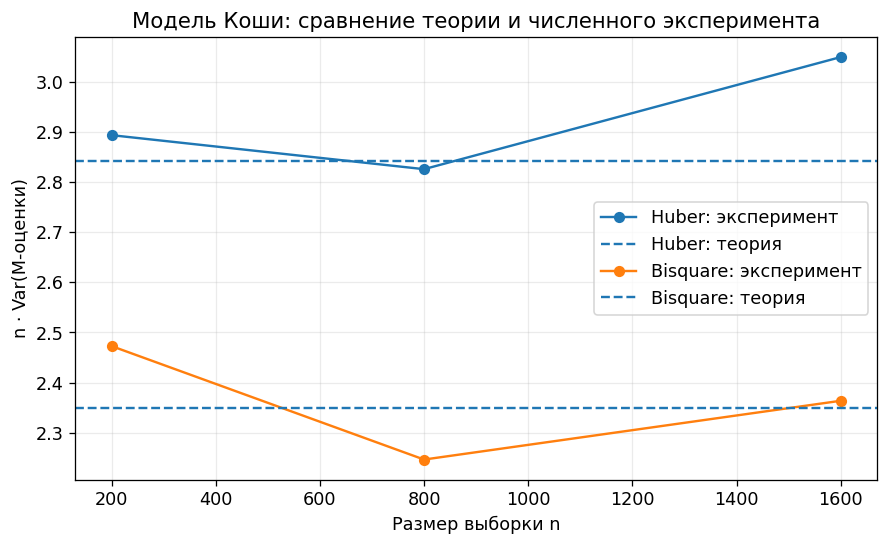

In [24]:
def cauchy_psi_moments(kind, c):
    dens = lambda z: 1 / (np.pi * (1 + z*z))
    if kind == "Huber":
        A = 2 * np.arctan(c) / np.pi
        B = (2 / np.pi) * (c - np.arctan(c)) + c*c * (1 - A)
    else:
        A = integrate.quad(lambda z: dpsi_bisquare(z, c) * dens(z), -c, c)[0]
        B = integrate.quad(lambda z: psi_bisquare(z, c)**2 * dens(z), -c, c)[0]
    return A, B

cauchy_theory = {}
for kind, c in [("Huber", c_huber), ("Bisquare", c_bisquare)]:
    A, B = cauchy_psi_moments(kind, c)
    cauchy_theory[kind] = B / A**2  # gamma=1

df_cauchy_theory = pd.DataFrame({
    "M-оценка": list(cauchy_theory),
    "Параметр c (из нормальной модели)": [c_huber, c_bisquare],
    "Теоретическое v² для Коши": list(cauchy_theory.values())
})
display(df_cauchy_theory.round(5))

rng_cauchy = np.random.default_rng(106)
N_CAUCHY = [200, 800, 1600]
REPEATS_CAUCHY = 900
records_cauchy = []
for n in N_CAUCHY:
    values = {"Huber": [], "Bisquare": []}
    for _ in range(REPEATS_CAUCHY):
        x = rng_cauchy.standard_cauchy(n)
        s = mad_scale(x, model="cauchy")
        values["Huber"].append(m_location(x, "Huber", c_huber, s))
        values["Bisquare"].append(m_location(x, "Bisquare", c_bisquare, s))
    for kind, est in values.items():
        empirical_v = n * np.var(est, ddof=1)
        records_cauchy.append({
            "n": n, "Оценка": kind,
            "Теоретическое v²": cauchy_theory[kind],
            "Эксперимент n·Var": empirical_v,
            "Относительная ошибка, %": 100 * (empirical_v / cauchy_theory[kind] - 1)
        })
df_cauchy_mc = pd.DataFrame(records_cauchy)
display(df_cauchy_mc.round(4))

plt.figure(figsize=(9, 5))
for kind in cauchy_theory:
    p = df_cauchy_mc[df_cauchy_mc["Оценка"] == kind]
    plt.plot(p["n"], p["Эксперимент n·Var"], 'o-', label=f"{kind}: эксперимент")
    plt.axhline(cauchy_theory[kind], linestyle='--', label=f"{kind}: теория")
plt.xlabel("Размер выборки n")
plt.ylabel("n · Var(M-оценки)")
plt.title("Модель Коши: сравнение теории и численного эксперимента")
plt.legend()
plt.show()

В численном эксперименте полученные значения оказались близки к теоретическим. Например, при размере выборки $n=1600$ эмпирическая дисперсия, умноженная на n, составила 3.0494 для Губера и 2.3638 для bisquare.

Относительная ошибка для bisquare составила всего 0.57%, а для Губера — 7.28%. Небольшие колебания результатов при увеличении выборки связаны со случайностью моделирования.

Несмотря на отсутствие конечной дисперсии у самого распределения Коши, исследуемые робастные M-оценки обладают конечной асимптотической дисперсией.

### Результат

В нормальной модели параметры Huber и bisquare, обеспечивающие 95% асимптотической эффективности, сохранили устойчивость при точечном загрязнении. При переходе к распределению Коши робастные оценки положения имели конечную асимптотическую дисперсию, согласующуюся с симуляциями. Реакция Huber и bisquare на удалённые загрязнения различалась из-за формы их функций влияния.


---

## Итоги

В рассмотренных сценариях среднее показало высокую точность при чистой нормальной модели, но сильнее реагировало на выбросы. Медиана и M-оценки ограничивали влияние загрязнения; breakdown point медианы составил около 50%.

Для Huber и bisquare также исследованы функции влияния, асимптотическая дисперсия, настройка эффективности и поведение при тяжёлых хвостах. Эти результаты показывают компромисс между эффективностью на нормальных данных и устойчивостью к загрязнению; они относятся к заданным моделям и настройкам.
